In [ ]:
from google.colab import drive

drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/BrainTumor_BO_Reproduction"
DATASET_DIR = os.path.join(BASE_DIR, "dataset")

print("Base directory:", BASE_DIR)
print("Dataset directory:", DATASET_DIR)

Base directory: /content/drive/MyDrive/BrainTumor_BO_Reproduction
Dataset directory: /content/drive/MyDrive/BrainTumor_BO_Reproduction/dataset


In [ ]:
import os
import zipfile

ZIP_PATH = os.path.join(DATASET_DIR, "dataset2.zip")
EXTRACT_DIR = "/content/brain_tumor_dataset2"

print("ZIP file exists:", os.path.exists(ZIP_PATH))
print("ZIP path:", ZIP_PATH)

if not os.path.exists(EXTRACT_DIR):
    os.makedirs(EXTRACT_DIR)

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

    print("Dataset 2 extracted successfully!")
else:
    print("Dataset 2 is already extracted.")

print("Extraction directory:", EXTRACT_DIR)

ZIP file exists: True
ZIP path: /content/drive/MyDrive/BrainTumor_BO_Reproduction/dataset/dataset2.zip
Dataset 2 is already extracted.
Extraction directory: /content/brain_tumor_dataset2


In [ ]:
import os

print("DATASET 2 FOLDER STRUCTURE")
print("=" * 60)

for root, dirs, files in os.walk(EXTRACT_DIR):
    level = root.replace(EXTRACT_DIR, "").count(os.sep)
    indent = "    " * level
    print(indent + os.path.basename(root) + "/")

    if level < 2:
        for file in files[:5]:
            print(indent + "    " + file)

DATASET 2 FOLDER STRUCTURE
brain_tumor_dataset2/
    Training/
        glioma/
        pituitary/
        notumor/
        meningioma/
    Testing/
        glioma/
        pituitary/
        notumor/
        meningioma/


In [ ]:
import os

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

print("IMAGE COUNT BY SPLIT AND CLASS")
print("=" * 60)

for split in ["Training", "Testing"]:

    split_path = os.path.join(EXTRACT_DIR, split)

    print(f"\n{split}:")

    total = 0

    for class_name in sorted(os.listdir(split_path)):

        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):

            count = len([
                f for f in os.listdir(class_path)
                if f.lower().endswith(IMAGE_EXTENSIONS)
            ])

            print(f"    {class_name}: {count}")

            total += count

    print(f"    Total {split}: {total}")

IMAGE COUNT BY SPLIT AND CLASS

Training:
    glioma: 1400
    meningioma: 1400
    notumor: 1400
    pituitary: 1400
    Total Training: 5600

Testing:
    glioma: 400
    meningioma: 400
    notumor: 400
    pituitary: 400
    Total Testing: 1600


In [ ]:
import os
import pandas as pd

image_data = []

for split in ["Training", "Testing"]:

    split_path = os.path.join(EXTRACT_DIR, split)

    for class_name in os.listdir(split_path):

        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):

            for filename in os.listdir(class_path):

                if filename.lower().endswith((".jpg", ".jpeg", ".png")):

                    image_data.append({
                        "path": os.path.join(class_path, filename),
                        "class": class_name,
                        "split": split
                    })

df = pd.DataFrame(image_data)

print("DataFrame created successfully!")
print("Total images:", len(df))

print("\nClass distribution:")
print(df["class"].value_counts())

print("\nSplit distribution:")
print(df["split"].value_counts())

display(df.head())

DataFrame created successfully!
Total images: 7200

Class distribution:
class
glioma        1800
pituitary     1800
notumor       1800
meningioma    1800
Name: count, dtype: int64

Split distribution:
split
Training    5600
Testing     1600
Name: count, dtype: int64


,path,class,split
0,/content/brain_tumor_dataset2/Training/glioma/...,glioma,Training
1,/content/brain_tumor_dataset2/Training/glioma/...,glioma,Training
2,/content/brain_tumor_dataset2/Training/glioma/...,glioma,Training
3,/content/brain_tumor_dataset2/Training/glioma/...,glioma,Training
4,/content/brain_tumor_dataset2/Training/glioma/...,glioma,Training


In [ ]:
from sklearn.model_selection import train_test_split

original_train_df = df[df["split"] == "Training"].copy()
test_df = df[df["split"] == "Testing"].copy()

train_df, val_df = train_test_split(
    original_train_df,
    test_size=571,
    stratify=original_train_df["class"],
    random_state=42
)


train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("=" * 60)
print("FINAL DATASET SPLIT")
print("=" * 60)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Total images:", len(train_df) + len(val_df) + len(test_df))

print("\nTraining class distribution:")
print(train_df["class"].value_counts())

print("\nValidation class distribution:")
print(val_df["class"].value_counts())

print("\nTesting class distribution:")
print(test_df["class"].value_counts())

FINAL DATASET SPLIT
Training images: 5029
Validation images: 571
Testing images: 1600
Total images: 7200

Training class distribution:
class
meningioma    1258
glioma        1257
pituitary     1257
notumor       1257
Name: count, dtype: int64

Validation class distribution:
class
notumor       143
glioma        143
pituitary     143
meningioma    142
Name: count, dtype: int64

Testing class distribution:
class
glioma        400
pituitary     400
notumor       400
meningioma    400
Name: count, dtype: int64


In [ ]:


from PIL import Image
from collections import Counter

image_sizes = []


for path in df["path"]:
    try:
        with Image.open(path) as img:
            image_sizes.append(img.size)
    except Exception as e:
        print("Could not read:", path)

size_counts = Counter(image_sizes)

print("=" * 60)
print("IMAGE DIMENSION ANALYSIS")
print("=" * 60)

print("Total images checked:", len(image_sizes))
print("Number of unique image sizes:", len(size_counts))

print("\nMost common image sizes:")
for size, count in size_counts.most_common(15):
    print(f"{size}: {count} images")

IMAGE DIMENSION ANALYSIS
Total images checked: 7200
Number of unique image sizes: 447

Most common image sizes:
(512, 512): 5014 images
(225, 225): 338 images
(630, 630): 90 images
(201, 251): 57 images
(228, 221): 51 images
(232, 217): 50 images
(442, 442): 48 images
(236, 236): 48 images
(150, 198): 44 images
(200, 252): 43 images
(428, 417): 42 images
(227, 222): 39 images
(173, 201): 36 images
(206, 244): 35 images
(256, 256): 33 images


In [ ]:
IMG_SIZE = (224, 224)

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

NUM_CLASSES = len(CLASS_NAMES)

BATCH_SIZE = 8

print("Image size:", IMG_SIZE)
print("Class names:", CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)
print("Batch size:", BATCH_SIZE)

Image size: (224, 224)
Class names: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4
Batch size: 8


In [ ]:
import tensorflow as tf
import numpy as np


class_to_label = {
    class_name: index
    for index, class_name in enumerate(CLASS_NAMES)
}

print("Class mapping:")
print(class_to_label)


def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )


    image = tf.cast(image, tf.float32) / 255.0

    return image, label

def create_tf_dataset(dataframe, shuffle=False):

    paths = dataframe["path"].values

    labels = np.array([
        class_to_label[class_name]
        for class_name in dataframe["class"]
    ])

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


train_ds = create_tf_dataset(
    train_df,
    shuffle=True
)

val_ds = create_tf_dataset(
    val_df,
    shuffle=False
)

test_ds = create_tf_dataset(
    test_df,
    shuffle=False
)


print("\nData pipeline created successfully!")

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

Class mapping:
{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}

Data pipeline created successfully!
Training images: 5029
Validation images: 571
Testing images: 1600
Image size: (224, 224)
Batch size: 8
Number of classes: 4


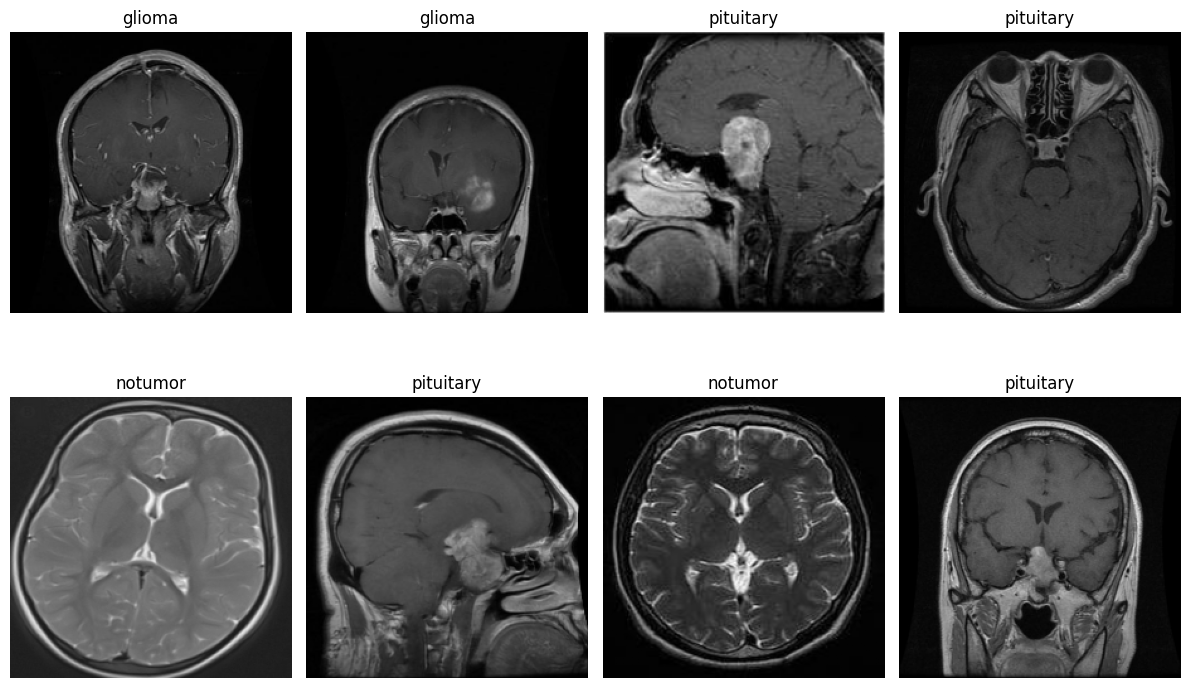

In [ ]:
import matplotlib.pyplot as plt


images, labels = next(iter(train_ds))


num_images = len(images)

plt.figure(figsize=(12, 8))

for i in range(num_images):
    plt.subplot(2, 4, i + 1)

    plt.imshow(images[i].numpy())

    class_index = int(labels[i].numpy())
    plt.title(CLASS_NAMES[class_index])

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


def build_cnn(
    num_conv_layers,
    kernel_sizes,
    filter_sizes,
    dropout_rate,
    dense1_units,
    dense2_units
):

    model = keras.Sequential(
        name=f"CNN_{num_conv_layers}_ConvLayers"
    )

    model.add(
        layers.Input(
            shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
        )
    )

    for i in range(num_conv_layers):

        model.add(
            layers.Conv2D(
                filters=filter_sizes[i],
                kernel_size=kernel_sizes[i],
                padding="same",
                activation="relu"
            )
        )

        model.add(
            layers.BatchNormalization()
        )

        if (i + 1) % 2 == 0:
            model.add(
                layers.MaxPooling2D(
                    pool_size=(2, 2)
                )
            )

    model.add(
        layers.Flatten()
    )


    model.add(
        layers.Dense(
            dense1_units,
            activation="relu"
        )
    )


    model.add(
        layers.Dropout(dropout_rate)
    )


    model.add(
        layers.Dense(
            dense2_units,
            activation="relu"
        )
    )

    model.add(
        layers.Dense(
            NUM_CLASSES,
            activation="softmax"
        )
    )


    optimizer = keras.optimizers.SGD(
        learning_rate=0.0001,
        momentum=0.9,
        nesterov=True
    )

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


print("Flexible CNN builder created successfully!")

Flexible CNN builder created successfully!


In [ ]:
# Create a small test configuration
test_conv_layers = 5

test_kernel_sizes = [
    (3, 3),
    (3, 3),
    (3, 3),
    (3, 3),
    (3, 3)
]

test_filter_sizes = [
    32,
    32,
    64,
    64,
    128
]

test_dropout_rate = 0.2
test_dense1_units = 128
test_dense2_units = 64


test_model = build_cnn(
    num_conv_layers=test_conv_layers,
    kernel_sizes=test_kernel_sizes,
    filter_sizes=test_filter_sizes,
    dropout_rate=test_dropout_rate,
    dense1_units=test_dense1_units,
    dense2_units=test_dense2_units
)


test_model.summary()


test_history = test_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=1
)


print("\n" + "=" * 60)
print("1-EPOCH CNN TEST COMPLETED")
print("=" * 60)

print(
    "Training accuracy:",
    test_history.history["accuracy"][-1]
)

print(
    "Validation accuracy:",
    test_history.history["val_accuracy"][-1]
)

print(
    "Training loss:",
    test_history.history["loss"][-1]
)

print(
    "Validation loss:",
    test_history.history["val_loss"][-1]
)

Model: "CNN_5_ConvLayers"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 401408)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    51,380,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,529,572 (196.57 MB)

 Trainable params: 51,528,932 (196.57 MB)

 Non-trainable params: 640 (2.50 KB)

629/629 ━━━━━━━━━━━━━━━━━━━━ 69s 72ms/step - accuracy: 0.7992 - loss: 0.5272 - val_accuracy: 0.8862 - val_loss: 0.3290

1-EPOCH CNN TEST COMPLETED
Training accuracy: 0.7991648316383362
Validation accuracy: 0.8861646056175232
Training loss: 0.527195394039154
Validation loss: 0.32895222306251526


In [ ]:
import random

SEARCH_SPACE = {
    "conv_layers": [5, 7, 9, 11],

    "kernel_sizes": [
        (3, 3),
        (5, 5)
    ],

    "filters": list(range(16, 257, 16)),

    "dropout": [
        0.0,
        0.2,
        0.3,
        0.4,
        0.5,
        0.6
    ],

    "optimizer": [
        "Adam",
        "SGD_Nesterov"
    ],

    "learning_rate": [
        0.001,
        0.0001
    ]
}


print("=" * 60)
print("BAYESIAN OPTIMIZATION SEARCH SPACE")
print("=" * 60)

print("\nConvolutional layers:")
print(SEARCH_SPACE["conv_layers"])

print("\nKernel sizes:")
print(SEARCH_SPACE["kernel_sizes"])

print("\nFilter values:")
print(SEARCH_SPACE["filters"])

print("\nDropout values:")
print(SEARCH_SPACE["dropout"])

print("\nOptimizers:")
print(SEARCH_SPACE["optimizer"])

print("\nLearning rates:")
print(SEARCH_SPACE["learning_rate"])

BAYESIAN OPTIMIZATION SEARCH SPACE

Convolutional layers:
[5, 7, 9, 11]

Kernel sizes:
[(3, 3), (5, 5)]

Filter values:
[16, 32, 48, 64, 80, 96, 112, 128, 144, 160, 176, 192, 208, 224, 240, 256]

Dropout values:
[0.0, 0.2, 0.3, 0.4, 0.5, 0.6]

Optimizers:
['Adam', 'SGD_Nesterov']

Learning rates:
[0.001, 0.0001]


In [ ]:
def generate_random_config():
    """
    Generate one random CNN configuration
    from the Bayesian Optimization search space.
    """

    num_conv_layers = random.choice(
        SEARCH_SPACE["conv_layers"]
    )

    kernel_sizes = [
        random.choice(SEARCH_SPACE["kernel_sizes"])
        for _ in range(num_conv_layers)
    ]


    filters = [
        random.choice(SEARCH_SPACE["filters"])
        for _ in range(num_conv_layers)
    ]

    dropout1 = random.choice(
        SEARCH_SPACE["dropout"]
    )

    dropout2 = random.choice(
        SEARCH_SPACE["dropout"]
    )


    dense1 = random.choice(
        [64, 96, 128, 160, 192, 208, 224, 256]
    )

    dense2 = random.choice(
        [32, 48, 64, 80, 96, 112, 128]
    )


    optimizer = random.choice(
        SEARCH_SPACE["optimizer"]
    )

    learning_rate = random.choice(
        SEARCH_SPACE["learning_rate"]
    )

    config = {
        "conv_layers": num_conv_layers,
        "kernel_sizes": kernel_sizes,
        "filters": filters,
        "dropout1": dropout1,
        "dense1": dense1,
        "dropout2": dropout2,
        "dense2": dense2,
        "optimizer": optimizer,
        "learning_rate": learning_rate
    }

    return config

random.seed(42)

initial_configs = [
    generate_random_config()
    for _ in range(5)
]


print("=" * 70)
print("5 INITIAL BAYESIAN OPTIMIZATION CONFIGURATIONS")
print("=" * 70)

for i, config in enumerate(initial_configs, start=1):

    print(f"\nConfiguration {i}")
    print("-" * 50)

    for key, value in config.items():
        print(f"{key}: {value}")

5 INITIAL BAYESIAN OPTIMIZATION CONFIGURATIONS

Configuration 1
--------------------------------------------------
conv_layers: 5
kernel_sizes: [(3, 3), (5, 5), (3, 3), (3, 3), (3, 3)]
filters: [64, 48, 224, 32, 16]
dropout1: 0.0
dense1: 160
dropout2: 0.2
dense2: 96
optimizer: Adam
learning_rate: 0.001

Configuration 2
--------------------------------------------------
conv_layers: 11
kernel_sizes: [(3, 3), (5, 5), (5, 5), (3, 3), (3, 3), (5, 5), (5, 5), (5, 5), (3, 3), (3, 3), (5, 5)]
filters: [64, 48, 208, 64, 192, 192, 144, 32, 240, 64, 208]
dropout1: 0.0
dense1: 192
dropout2: 0.5
dense2: 128
optimizer: SGD_Nesterov
learning_rate: 0.001

Configuration 3
--------------------------------------------------
conv_layers: 5
kernel_sizes: [(3, 3), (3, 3), (5, 5), (3, 3), (3, 3)]
filters: [64, 208, 144, 240, 192]
dropout1: 0.2
dense1: 208
dropout2: 0.3
dense2: 48
optimizer: SGD_Nesterov
learning_rate: 0.001

Configuration 4
--------------------------------------------------
conv_layers: 7
k

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models


def build_cnn(config):
    """
    Build CNN according to the selected configuration.
    """

    model = models.Sequential()

    model.add(
        layers.Input(
            shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
        )
    )


    for i in range(config["conv_layers"]):

        model.add(
            layers.Conv2D(
                filters=config["filters"][i],
                kernel_size=config["kernel_sizes"][i],
                padding="same",
                activation="relu"
            )
        )

        model.add(
            layers.BatchNormalization()
        )


        if (i + 1) % 2 == 0:
            model.add(
                layers.MaxPooling2D(
                    pool_size=(2, 2)
                )
            )


    model.add(
        layers.Dropout(config["dropout1"])
    )

    model.add(
        layers.Flatten()
    )

    model.add(
        layers.Dense(
            config["dense1"],
            activation="relu"
        )
    )

    model.add(
        layers.Dropout(config["dropout2"])
    )

    model.add(
        layers.Dense(
            config["dense2"],
            activation="relu"
        )
    )

    model.add(
        layers.Dense(
            NUM_CLASSES,
            activation="softmax"
        )
    )



    if config["optimizer"] == "Adam":

        optimizer = tf.keras.optimizers.Adam(
            learning_rate=config["learning_rate"]
        )

    else:

        optimizer = tf.keras.optimizers.SGD(
            learning_rate=config["learning_rate"],
            momentum=0.9,
            nesterov=True
        )


    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
def evaluate_configuration(config, epochs=1):

    print("\n" + "=" * 70)
    print("EVALUATING CONFIGURATION")
    print("=" * 70)

    print("\nConfiguration:")
    for key, value in config.items():
        print(f"{key}: {value}")


    model = build_cnn(config)


    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        verbose=1
    )

    validation_accuracy = history.history["val_accuracy"][-1]

    print(
        f"\nValidation Accuracy: "
        f"{validation_accuracy:.4f}"
    )

    del model
    tf.keras.backend.clear_session()

    return validation_accuracy

In [ ]:
initial_scores = []

for i, config in enumerate(initial_configs, start=1):

    print("\n")
    print("#" * 70)
    print(f"CONFIGURATION {i} / 5")
    print("#" * 70)

    score = evaluate_configuration(
        config,
        epochs=1
    )

    initial_scores.append(score)

    print(
        f"\nConfiguration {i} "
        f"Validation Accuracy = {score:.4f}"
    )


print("\n" + "=" * 70)
print("INITIAL CONFIGURATION RESULTS")
print("=" * 70)

for i, score in enumerate(initial_scores, start=1):

    print(
        f"Configuration {i}: "
        f"{score:.4f}"
    )

print("\nBest initial validation accuracy:",
      max(initial_scores))

print(
    "Best initial configuration:",
    initial_scores.index(max(initial_scores)) + 1
)



######################################################################
CONFIGURATION 1 / 5
######################################################################

EVALUATING CONFIGURATION

Configuration:
conv_layers: 5
kernel_sizes: [(3, 3), (5, 5), (3, 3), (3, 3), (3, 3)]
filters: [64, 48, 224, 32, 16]
dropout1: 0.0
dense1: 160
dropout2: 0.2
dense2: 96
optimizer: Adam
learning_rate: 0.001
629/629 ━━━━━━━━━━━━━━━━━━━━ 110s 126ms/step - accuracy: 0.6162 - loss: 1.4894 - val_accuracy: 0.6480 - val_loss: 0.7360

Validation Accuracy: 0.6480

Configuration 1 Validation Accuracy = 0.6480


######################################################################
CONFIGURATION 2 / 5
######################################################################

EVALUATING CONFIGURATION

Configuration:
conv_layers: 11
kernel_sizes: [(3, 3), (5, 5), (5, 5), (3, 3), (3, 3), (5, 5), (5, 5), (5, 5), (3, 3), (3, 3), (5, 5)]
filters: [64, 48, 208, 64, 192, 192, 144, 32, 240, 64, 208]
dropout1: 0.0
dense1: 19

In [ ]:
import numpy as np

def encode_configuration(config):

    features = []


    features.append(config["conv_layers"])

    for kernel in config["kernel_sizes"]:
        features.append(kernel[0])


    while len(features) < 1 + 11:
        features.append(0)


    for f in config["filters"]:
        features.append(f)


    current_filter_count = len(config["filters"])

    for _ in range(11 - current_filter_count):
        features.append(0)


    features.append(config["dropout1"])
    features.append(config["dropout2"])


    features.append(config["dense1"])
    features.append(config["dense2"])


    if config["optimizer"] == "Adam":
        features.append(0)
    else:
        features.append(1)


    features.append(config["learning_rate"])

    return np.array(features, dtype=np.float64)


X_initial = np.array([
    encode_configuration(config)
    for config in initial_configs
])


y_initial = np.array(initial_scores)



print("=" * 70)
print("CONFIGURATION ENCODING")
print("=" * 70)

print("\nX_initial shape:", X_initial.shape)
print("y_initial shape:", y_initial.shape)

print("\nEncoded configurations:")
print(X_initial)

print("\nValidation accuracies:")
print(y_initial)

CONFIGURATION ENCODING

X_initial shape: (5, 29)
y_initial shape: (5,)

Encoded configurations:
[[5.00e+00 3.00e+00 5.00e+00 3.00e+00 3.00e+00 3.00e+00 0.00e+00 0.00e+00
  0.00e+00 0.00e+00 0.00e+00 0.00e+00 6.40e+01 4.80e+01 2.24e+02 3.20e+01
  1.60e+01 0.00e+00 0.00e+00 0.00e+00 0.00e+00 0.00e+00 0.00e+00 0.00e+00
  2.00e-01 1.60e+02 9.60e+01 0.00e+00 1.00e-03]
 [1.10e+01 3.00e+00 5.00e+00 5.00e+00 3.00e+00 3.00e+00 5.00e+00 5.00e+00
  5.00e+00 3.00e+00 3.00e+00 5.00e+00 6.40e+01 4.80e+01 2.08e+02 6.40e+01
  1.92e+02 1.92e+02 1.44e+02 3.20e+01 2.40e+02 6.40e+01 2.08e+02 0.00e+00
  5.00e-01 1.92e+02 1.28e+02 1.00e+00 1.00e-03]
 [5.00e+00 3.00e+00 3.00e+00 5.00e+00 3.00e+00 3.00e+00 0.00e+00 0.00e+00
  0.00e+00 0.00e+00 0.00e+00 0.00e+00 6.40e+01 2.08e+02 1.44e+02 2.40e+02
  1.92e+02 0.00e+00 0.00e+00 0.00e+00 0.00e+00 0.00e+00 0.00e+00 2.00e-01
  3.00e-01 2.08e+02 4.80e+01 1.00e+00 1.00e-03]
 [7.00e+00 3.00e+00 3.00e+00 5.00e+00 5.00e+00 5.00e+00 3.00e+00 5.00e+00
  0.00e+00 0.00e+00 

In [ ]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_initial_scaled = scaler.fit_transform(X_initial)



kernel = (
    ConstantKernel(1.0)
    * Matern(
        length_scale=1.0,
        nu=2.5
    )
)


gp = GaussianProcessRegressor(
    kernel=kernel,
    alpha=1e-6,
    normalize_y=True,
    random_state=42,
    n_restarts_optimizer=5
)


gp.fit(
    X_initial_scaled,
    y_initial
)


print("=" * 70)
print("GAUSSIAN PROCESS FITTED SUCCESSFULLY")
print("=" * 70)

print("\nNumber of configurations used:", len(X_initial))
print("Number of features:", X_initial.shape[1])

print("\nBest observed validation accuracy:",
      np.max(y_initial))

print("\nBest initial configuration:",
      np.argmax(y_initial) + 1)

print("\nLearned GP kernel:")
print(gp.kernel_)

GAUSSIAN PROCESS FITTED SUCCESSFULLY

Number of configurations used: 5
Number of features: 29

Best observed validation accuracy: 0.793345034122467

Best initial configuration: 5

Learned GP kernel:
1**2 * Matern(length_scale=3.82, nu=2.5)


In [ ]:
from scipy.stats import norm
import numpy as np


def expected_improvement(
    X_candidates,
    gp,
    best_score,
    xi=0.01
):



    X_candidates_scaled = scaler.transform(
        X_candidates
    )


    mean, std = gp.predict(
        X_candidates_scaled,
        return_std=True
    )


    std = np.maximum(std, 1e-9)


    improvement = (
        mean
        - best_score
        - xi
    )


    z = improvement / std

    ei = (
        improvement * norm.cdf(z)
        + std * norm.pdf(z)
    )

    return ei, mean, std


NUM_CANDIDATES = 100

candidate_configs = [
    generate_random_config()
    for _ in range(NUM_CANDIDATES)
]



X_candidates = np.array([
    encode_configuration(config)
    for config in candidate_configs
])




best_score = np.max(y_initial)



ei_values, predicted_mean, predicted_std = (
    expected_improvement(
        X_candidates,
        gp,
        best_score
    )
)



best_candidate_index = np.argmax(ei_values)


print("=" * 70)
print("EXPECTED IMPROVEMENT CALCULATION")
print("=" * 70)

print("\nCurrent best validation accuracy:")
print(best_score)

print("\nNumber of candidates:")
print(NUM_CANDIDATES)

print("\nBest candidate index:")
print(best_candidate_index)

print("\nPredicted validation accuracy:")
print(
    predicted_mean[best_candidate_index]
)

print("\nPredicted uncertainty:")
print(
    predicted_std[best_candidate_index]
)

print("\nExpected Improvement:")
print(
    ei_values[best_candidate_index]
)


print("\nSelected candidate configuration:")
print("-" * 50)

selected_config = candidate_configs[
    best_candidate_index
]

for key, value in selected_config.items():
    print(f"{key}: {value}")

EXPECTED IMPROVEMENT CALCULATION

Current best validation accuracy:
0.793345034122467

Number of candidates:
100

Best candidate index:
41

Predicted validation accuracy:
0.7393148373212302

Predicted uncertainty:
0.049615154615560236

Expected Improvement:
0.002304707360289161

Selected candidate configuration:
--------------------------------------------------
conv_layers: 11
kernel_sizes: [(3, 3), (5, 5), (5, 5), (5, 5), (5, 5), (5, 5), (3, 3), (5, 5), (3, 3), (3, 3), (3, 3)]
filters: [48, 224, 64, 192, 80, 32, 176, 64, 224, 192, 224]
dropout1: 0.6
dense1: 192
dropout2: 0.0
dense2: 96
optimizer: SGD_Nesterov
learning_rate: 0.0001


In [ ]:
TOTAL_CONFIGURATIONS = 20
NUM_CANDIDATES = 100
BO_EPOCHS = 1

print("=" * 70)
print("AUTOMATIC BAYESIAN OPTIMIZATION")
print("=" * 70)



bo_results = []

for config, score in zip(
    initial_configs,
    initial_scores
):

    result = config.copy()
    result["validation_accuracy"] = score

    bo_results.append(result)


first_bo_config = selected_config

print("\nStarting Bayesian Optimization...")
print(
    f"Already evaluated: "
    f"{len(bo_results)} / {TOTAL_CONFIGURATIONS}"
)


while len(bo_results) < TOTAL_CONFIGURATIONS:

    current_number = len(bo_results) + 1

    print("\n")
    print("=" * 70)
    print(
        f"BO → EVALUATING CONFIGURATION "
        f"{current_number} / {TOTAL_CONFIGURATIONS}"
    )
    print("=" * 70)



    if current_number == 6:

        next_config = first_bo_config

        print("\nUsing configuration selected in STEP 19.")

    else:


        candidate_configs = [
            generate_random_config()
            for _ in range(NUM_CANDIDATES)
        ]

        evaluated_keys = {
            str(config)
            for config in [
                {
                    key: value
                    for key, value in result.items()
                    if key != "validation_accuracy"
                }
                for result in bo_results
            ]
        }


        candidate_configs = [
            config
            for config in candidate_configs
            if str(config) not in evaluated_keys
        ]


        X_candidates = np.array([
            encode_configuration(config)
            for config in candidate_configs
        ])




        current_scores = np.array([
            result["validation_accuracy"]
            for result in bo_results
        ])

        best_score = np.max(current_scores)



        ei_values, predicted_mean, predicted_std = (
            expected_improvement(
                X_candidates,
                gp,
                best_score
            )
        )


        best_candidate_index = np.argmax(
            ei_values
        )

        next_config = candidate_configs[
            best_candidate_index
        ]


        print("\nSelected by Expected Improvement:")

        print(
            "Predicted mean:",
            predicted_mean[
                best_candidate_index
            ]
        )

        print(
            "Predicted uncertainty:",
            predicted_std[
                best_candidate_index
            ]
        )

        print(
            "Expected Improvement:",
            ei_values[
                best_candidate_index
            ]
        )


    print("\nSelected configuration:")

    for key, value in next_config.items():
        print(f"{key}: {value}")




    score = evaluate_configuration(
        next_config,
        epochs=BO_EPOCHS
    )


    print(
        f"\nActual validation accuracy: "
        f"{score:.4f}"
    )


    bo_results.append({
        **next_config,
        "validation_accuracy": score
    })


    all_configs = [
        {
            key: value
            for key, value in result.items()
            if key != "validation_accuracy"
        }
        for result in bo_results
    ]

    all_scores = np.array([
        result["validation_accuracy"]
        for result in bo_results
    ])




    X_all = np.array([
        encode_configuration(config)
        for config in all_configs
    ])




    X_all_scaled = scaler.fit_transform(
        X_all
    )


    gp.fit(
        X_all_scaled,
        all_scores
    )



    best_index = np.argmax(
        all_scores
    )

    print("\nCurrent best configuration:")
    print(
        f"Configuration {best_index + 1}"
    )

    print(
        f"Validation accuracy: "
        f"{all_scores[best_index]:.4f}"
    )

    print(
        f"\nProgress: "
        f"{len(bo_results)} / "
        f"{TOTAL_CONFIGURATIONS}"
    )


all_scores = np.array([
    result["validation_accuracy"]
    for result in bo_results
])

best_index = np.argmax(
    all_scores
)

best_config = {
    key: value
    for key, value in bo_results[best_index].items()
    if key != "validation_accuracy"
}

best_validation_accuracy = (
    all_scores[best_index]
)


print("\n")
print("=" * 70)
print("BAYESIAN OPTIMIZATION FINISHED")
print("=" * 70)

print(
    "\nTotal configurations evaluated:",
    len(bo_results)
)

print(
    "\nBest configuration:",
    best_index + 1
)

print(
    "Best validation accuracy:",
    f"{best_validation_accuracy:.4f}"
)

print("\nBest configuration parameters:")
print("-" * 50)

for key, value in best_config.items():
    print(f"{key}: {value}")

AUTOMATIC BAYESIAN OPTIMIZATION

Starting Bayesian Optimization...
Already evaluated: 5 / 20


BO → EVALUATING CONFIGURATION 6 / 20

Using configuration selected in STEP 19.

Selected configuration:
conv_layers: 11
kernel_sizes: [(3, 3), (5, 5), (5, 5), (5, 5), (5, 5), (5, 5), (3, 3), (5, 5), (3, 3), (3, 3), (3, 3)]
filters: [48, 224, 64, 192, 80, 32, 176, 64, 224, 192, 224]
dropout1: 0.6
dense1: 192
dropout2: 0.0
dense2: 96
optimizer: SGD_Nesterov
learning_rate: 0.0001

EVALUATING CONFIGURATION

Configuration:
conv_layers: 11
kernel_sizes: [(3, 3), (5, 5), (5, 5), (5, 5), (5, 5), (5, 5), (3, 3), (5, 5), (3, 3), (3, 3), (3, 3)]
filters: [48, 224, 64, 192, 80, 32, 176, 64, 224, 192, 224]
dropout1: 0.6
dense1: 192
dropout2: 0.0
dense2: 96
optimizer: SGD_Nesterov
learning_rate: 0.0001
629/629 ━━━━━━━━━━━━━━━━━━━━ 302s 390ms/step - accuracy: 0.6781 - loss: 0.8252 - val_accuracy: 0.7776 - val_loss: 0.5470

Validation Accuracy: 0.7776

Actual validation accuracy: 0.7776

Current best configu

In [ ]:
import pandas as pd
import numpy as np

print("=" * 70)
print("STEP 22 — BEST CONFIGURATION")
print("=" * 70)


best_index = np.argmax(all_scores)

best_config = all_configs[best_index]

best_validation_accuracy = all_scores[best_index]


bo_results_df = pd.DataFrame(bo_results)


bo_results_sorted = bo_results_df.sort_values(
    by="validation_accuracy",
    ascending=False
).reset_index(drop=True)


print("\nAll configurations ranked by validation accuracy:")
print("-" * 70)

display(
    bo_results_sorted[
        ["conv_layers",
         "dropout1",
         "dense1",
         "dropout2",
         "dense2",
         "optimizer",
         "learning_rate",
         "validation_accuracy"]
    ]
)


print("\n" + "=" * 70)
print("BEST CONFIGURATION")
print("=" * 70)

print(
    "\nConfiguration number:",
    best_index + 1
)

print(
    "\nValidation accuracy:",
    f"{best_validation_accuracy:.4f}"
)

print("\nConfiguration parameters:")
print("-" * 50)

for key, value in best_config.items():
    print(f"{key}: {value}")

STEP 22 — BEST CONFIGURATION

All configurations ranked by validation accuracy:
----------------------------------------------------------------------


,conv_layers,dropout1,dense1,dropout2,dense2,optimizer,learning_rate,validation_accuracy
0,9,0.6,192,0.0,96,SGD_Nesterov,0.0001,0.854641
1,9,0.5,256,0.2,96,SGD_Nesterov,0.0010,0.826620
2,9,0.4,64,0.0,96,SGD_Nesterov,0.0001,0.816112
3,9,0.5,224,0.5,112,SGD_Nesterov,0.0001,0.812609
4,9,0.4,128,0.2,32,SGD_Nesterov,0.0001,0.807356
5,9,0.5,256,0.2,64,SGD_Nesterov,0.0001,0.805604
6,9,0.3,256,0.3,128,SGD_Nesterov,0.0001,0.802102
7,9,0.4,128,0.4,112,SGD_Nesterov,0.0010,0.800350
8,11,0.5,96,0.0,112,SGD_Nesterov,0.0001,0.793345
9,9,0.6,160,0.0,80,SGD_Nesterov,0.0010,0.786340



BEST CONFIGURATION

Configuration number: 15

Validation accuracy: 0.8546

Configuration parameters:
--------------------------------------------------
conv_layers: 9
kernel_sizes: [(3, 3), (5, 5), (5, 5), (5, 5), (3, 3), (5, 5), (3, 3), (5, 5), (3, 3)]
filters: [16, 32, 128, 208, 112, 192, 208, 144, 224]
dropout1: 0.6
dense1: 192
dropout2: 0.0
dense2: 96
optimizer: SGD_Nesterov
learning_rate: 0.0001


In [ ]:
print("=" * 70)
print("STEP 23 — BUILDING FINAL MODEL")
print("=" * 70)

final_model = build_cnn(best_config)

print("\nFinal model created successfully!")
print("\nBest configuration:")
for key, value in best_config.items():
    print(f"{key}: {value}")

print("\nModel summary:")
final_model.summary()

STEP 23 — BUILDING FINAL MODEL

Final model created successfully!

Best configuration:
conv_layers: 9
kernel_sizes: [(3, 3), (5, 5), (5, 5), (5, 5), (3, 3), (5, 5), (3, 3), (5, 5), (3, 3)]
filters: [16, 32, 128, 208, 112, 192, 208, 144, 224]
dropout1: 0.6
dense1: 192
dropout2: 0.0
dense2: 96
optimizer: SGD_Nesterov
learning_rate: 0.0001

Model summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │        12,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 128)  │       102,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 208)  │       665,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 208)  │           832 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 208)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 112)    │       209,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 112)    │           448 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 192)    │       537,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 192)    │           768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 192)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 208)    │       359,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 28, 28, 208)    │           832 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 144)    │       748,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 144)    │           576 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 144)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 14, 14, 224)    │       290,52

 Total params: 11,382,020 (43.42 MB)

 Trainable params: 11,379,492 (43.41 MB)

 Non-trainable params: 2,528 (9.88 KB)

In [ ]:
import tensorflow as tf

tf.keras.backend.clear_session()


best_config = {
    "conv_layers": 9,

    "kernel_sizes": [
        (3, 3),
        (5, 5),
        (5, 5),
        (5, 5),
        (3, 3),
        (5, 5),
        (3, 3),
        (5, 5),
        (3, 3)
    ],

    "filters": [
        16,
        32,
        128,
        208,
        112,
        192,
        208,
        144,
        224
    ],

    "dropout1": 0.6,
    "dense1": 192,
    "dropout2": 0.0,
    "dense2": 96,

    "optimizer": "SGD_Nesterov",
    "learning_rate": 0.0001
}

print("=" * 70)
print("BEST CONFIGURATION FROM BAYESIAN OPTIMIZATION")
print("=" * 70)

for key, value in best_config.items():
    print(f"{key}: {value}")

BEST CONFIGURATION FROM BAYESIAN OPTIMIZATION
conv_layers: 9
kernel_sizes: [(3, 3), (5, 5), (5, 5), (5, 5), (3, 3), (5, 5), (3, 3), (5, 5), (3, 3)]
filters: [16, 32, 128, 208, 112, 192, 208, 144, 224]
dropout1: 0.6
dense1: 192
dropout2: 0.0
dense2: 96
optimizer: SGD_Nesterov
learning_rate: 0.0001


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.backend.clear_session()

def build_final_cnn(config):

    model = models.Sequential()

    # Input
    model.add(
        layers.Input(
            shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
        )
    )



    for i in range(config["conv_layers"]):

        model.add(
            layers.Conv2D(
                filters=config["filters"][i],
                kernel_size=config["kernel_sizes"][i],
                padding="same",
                activation="relu"
            )
        )

        model.add(layers.BatchNormalization())

        if (i + 1) % 2 == 0:
            model.add(
                layers.MaxPooling2D(
                    pool_size=(2, 2)
                )
            )



    model.add(
        layers.Dropout(config["dropout1"])
    )

    model.add(layers.Flatten())

    model.add(
        layers.Dense(
            config["dense1"],
            activation="relu"
        )
    )

    model.add(
        layers.Dropout(config["dropout2"])
    )

    model.add(
        layers.Dense(
            config["dense2"],
            activation="relu"
        )
    )

    model.add(
        layers.Dense(
            NUM_CLASSES,
            activation="softmax"
        )
    )

    if config["optimizer"] == "SGD_Nesterov":

        optimizer = tf.keras.optimizers.SGD(
            learning_rate=config["learning_rate"],
            momentum=0.9,
            nesterov=True
        )

    else:

        optimizer = tf.keras.optimizers.Adam(
            learning_rate=config["learning_rate"]
        )


    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


final_model = build_final_cnn(best_config)

print("=" * 70)
print("FINAL CNN CREATED")
print("=" * 70)

final_model.summary()

FINAL CNN CREATED


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │        12,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 128)  │       102,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 208)  │       665,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 208)  │           832 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 208)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 112)    │       209,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 112)    │           448 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 192)    │       537,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 192)    │           768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 192)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 208)    │       359,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 28, 28, 208)    │           832 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 144)    │       748,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 144)    │           576 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 144)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 14, 14, 224)    │       290,52

 Total params: 11,382,020 (43.42 MB)

 Trainable params: 11,379,492 (43.41 MB)

 Non-trainable params: 2,528 (9.88 KB)

In [ ]:
FINAL_EPOCHS = 50

print("=" * 70)
print("FINAL MODEL TRAINING")
print("=" * 70)

print("Epochs:", FINAL_EPOCHS)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Batch size:", BATCH_SIZE)

history = final_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINAL_EPOCHS,
    verbose=1
)

print("\n" + "=" * 70)
print("FINAL TRAINING COMPLETED")
print("=" * 70)

FINAL MODEL TRAINING
Epochs: 50
Training images: 5029
Validation images: 571
Batch size: 8
Epoch 1/50
629/629 ━━━━━━━━━━━━━━━━━━━━ 167s 198ms/step - accuracy: 0.7210 - loss: 0.7047 - val_accuracy: 0.8039 - val_loss: 0.4661
Epoch 2/50
629/629 ━━━━━━━━━━━━━━━━━━━━ 110s 164ms/step - accuracy: 0.8204 - loss: 0.4474 - val_accuracy: 0.8792 - val_loss: 0.3246
Epoch 3/50
629/629 ━━━━━━━━━━━━━━━━━━━━ 111s 164ms/step - accuracy: 0.8662 - loss: 0.3327 - val_accuracy: 0.8967 - val_loss: 0.2655
Epoch 4/50
629/629 ━━━━━━━━━━━━━━━━━━━━ 111s 164ms/step - accuracy: 0.9022 - loss: 0.2490 - val_accuracy: 0.9072 - val_loss: 0.2033
Epoch 5/50
629/629 ━━━━━━━━━━━━━━━━━━━━ 111s 165ms/step - accuracy: 0.9294 - loss: 0.1787 - val_accuracy: 0.9177 - val_loss: 0.2591
Epoch 6/50
629/629 ━━━━━━━━━━━━━━━━━━━━ 111s 165ms/step - accuracy: 0.9411 - loss: 0.1546 - val_accuracy: 0.9335 - val_loss: 0.1789
Epoch 7/50
629/629 ━━━━━━━━━━━━━━━━━━━━ 111s 165ms/step - accuracy: 0.9594 - loss: 0.1152 - val_accuracy: 0.9527 - va

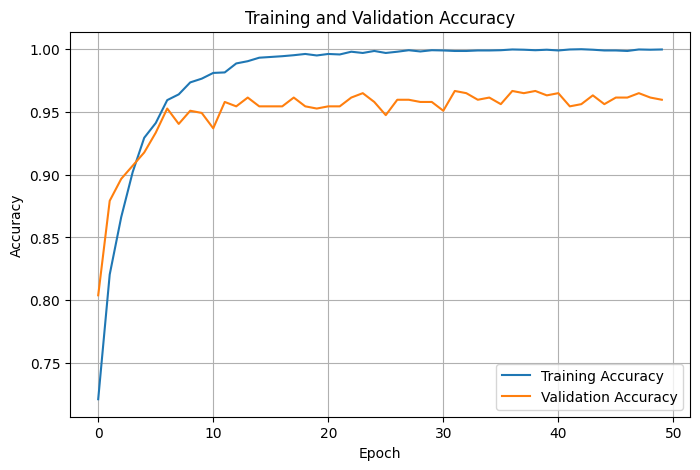

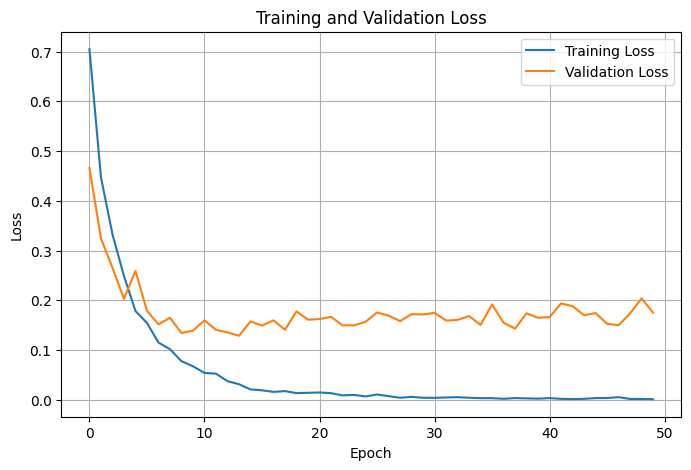

In [ ]:
# ============================================================
# STEP 24 — TRAINING & VALIDATION CURVES
# ============================================================

import matplotlib.pyplot as plt

# Accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print("=" * 70)
print("FINAL TEST EVALUATION")
print("=" * 70)

test_loss, test_accuracy = final_model.evaluate(
    test_ds,
    verbose=1
)

print("\n" + "=" * 70)
print("FINAL TEST RESULTS")
print("=" * 70)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")
print("=" * 70)

FINAL TEST EVALUATION
200/200 ━━━━━━━━━━━━━━━━━━━━ 9s 47ms/step - accuracy: 0.9144 - loss: 0.9268

FINAL TEST RESULTS
Test Loss     : 0.9268
Test Accuracy : 0.9144
Test Accuracy : 91.44%


In [ ]:
import numpy as np

print("=" * 70)
print("GENERATING TEST PREDICTIONS")
print("=" * 70)

y_prob = final_model.predict(
    test_ds,
    verbose=1
)

y_pred = np.argmax(y_prob, axis=1)


y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

print("\n" + "=" * 70)
print("PREDICTIONS GENERATED")
print("=" * 70)

print("Number of test samples :", len(y_true))
print("Number of predictions  :", len(y_pred))
print("Number of classes      :", NUM_CLASSES)

print("\nClass names:")
for i, class_name in enumerate(CLASS_NAMES):
    print(f"{i} → {class_name}")

print("=" * 70)

GENERATING TEST PREDICTIONS
200/200 ━━━━━━━━━━━━━━━━━━━━ 13s 52ms/step

PREDICTIONS GENERATED
Number of test samples : 1600
Number of predictions  : 1600
Number of classes      : 4

Class names:
0 → glioma
1 → meningioma
2 → notumor
3 → pituitary


CONFUSION MATRIX
[[307  39  48   6]
 [ 11 369   8  12]
 [  1   2 397   0]
 [  9   1   0 390]]


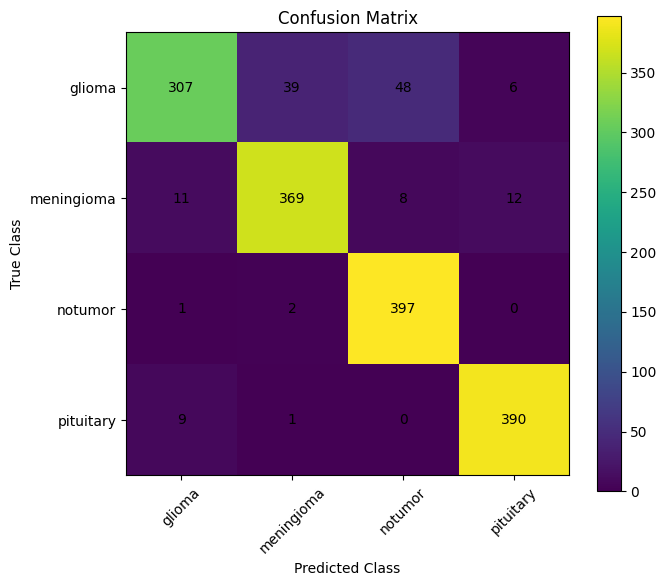

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

print("=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print(cm)

plt.figure(figsize=(7, 6))

plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix")
plt.colorbar()

plt.xticks(
    np.arange(NUM_CLASSES),
    CLASS_NAMES,
    rotation=45
)

plt.yticks(
    np.arange(NUM_CLASSES),
    CLASS_NAMES
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("=" * 70)
print("CLASSIFICATION METRICS")
print("=" * 70)

precision = precision_score(
    y_true,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_true,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_true,
    y_pred,
    average="weighted"
)

print(f"Weighted Precision : {precision:.4f}")
print(f"Weighted Recall    : {recall:.4f}")
print(f"Weighted F1-Score  : {f1:.4f}")

print("\n" + "=" * 70)
print("CLASS-WISE CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4
    )
)

CLASSIFICATION METRICS
Weighted Precision : 0.9165
Weighted Recall    : 0.9144
Weighted F1-Score  : 0.9124

CLASS-WISE CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma     0.9360    0.7675    0.8434       400
  meningioma     0.8978    0.9225    0.9100       400
     notumor     0.8764    0.9925    0.9308       400
   pituitary     0.9559    0.9750    0.9653       400

    accuracy                         0.9144      1600
   macro avg     0.9165    0.9144    0.9124      1600
weighted avg     0.9165    0.9144    0.9124      1600



In [ ]:
from sklearn.metrics import matthews_corrcoef, cohen_kappa_score

print("=" * 70)
print("ADDITIONAL EVALUATION METRICS")
print("=" * 70)

# Matthews Correlation Coefficient
mcc = matthews_corrcoef(y_true, y_pred)

# Cohen's Kappa
kappa = cohen_kappa_score(y_true, y_pred)

print(f"MCC (Matthews Correlation Coefficient) : {mcc:.4f}")
print(f"Cohen's Kappa                          : {kappa:.4f}")

print("=" * 70)

ADDITIONAL EVALUATION METRICS
MCC (Matthews Correlation Coefficient) : 0.8877
Cohen's Kappa                          : 0.8858


In [ ]:
print("=" * 80)
print("FINAL DATASET 2 RESULTS")
print("=" * 80)

print(f"Test Accuracy       : {test_accuracy * 100:.2f}%")
print(f"Test Loss           : {test_loss:.4f}")
print(f"Weighted Precision  : {precision * 100:.2f}%")
print(f"Weighted Recall     : {recall * 100:.2f}%")
print(f"Weighted F1-Score   : {f1 * 100:.2f}%")
print(f"MCC                 : {mcc:.4f}")
print(f"Cohen's Kappa       : {kappa:.4f}")

print("=" * 80)

FINAL DATASET 2 RESULTS
Test Accuracy       : 91.44%
Test Loss           : 0.9268
Weighted Precision  : 91.65%
Weighted Recall     : 91.44%
Weighted F1-Score   : 91.24%
MCC                 : 0.8877
Cohen's Kappa       : 0.8858


In [ ]:
paper_accuracy = 99.62
paper_f1 = 99.62
paper_mcc = 0.9949
paper_kappa = 0.9949

our_accuracy = test_accuracy * 100
our_f1 = f1 * 100
our_mcc = mcc
our_kappa = kappa

print("=" * 80)
print("DATASET 2 — REPRODUCTION vs ORIGINAL PAPER")
print("=" * 80)

print(f"{'Metric':<25} {'Paper':>15} {'Our Result':>15} {'Difference':>15}")
print("-" * 80)

print(
    f"{'Accuracy':<25} "
    f"{paper_accuracy:>14.2f}% "
    f"{our_accuracy:>14.2f}% "
    f"{our_accuracy - paper_accuracy:>14.2f}%"
)

print(
    f"{'F1-Score':<25} "
    f"{paper_f1:>14.2f}% "
    f"{our_f1:>14.2f}% "
    f"{our_f1 - paper_f1:>14.2f}%"
)

print(
    f"{'MCC':<25} "
    f"{paper_mcc:>15.4f} "
    f"{our_mcc:>15.4f} "
    f"{our_mcc - paper_mcc:>15.4f}"
)

print(
    f"{'Cohen Kappa':<25} "
    f"{paper_kappa:>15.4f} "
    f"{our_kappa:>15.4f} "
    f"{our_kappa - paper_kappa:>15.4f}"
)

print("=" * 80)

print("\nIMPORTANT:")
print("Paper Dataset 2 : 7,023 images / 1,311 test images")
print("Our Dataset 2   : 7,200 images / 1,600 test images")
print("Therefore, this is a reproduction comparison, not an exact split reproduction.")

DATASET 2 — REPRODUCTION vs ORIGINAL PAPER
Metric                              Paper      Our Result      Difference
--------------------------------------------------------------------------------
Accuracy                           99.62%          91.44%          -8.18%
F1-Score                           99.62%          91.24%          -8.38%
MCC                                0.9949          0.8877         -0.1072
Cohen Kappa                        0.9949          0.8858         -0.1091

IMPORTANT:
Paper Dataset 2 : 7,023 images / 1,311 test images
Our Dataset 2   : 7,200 images / 1,600 test images
Therefore, this is a reproduction comparison, not an exact split reproduction.


In [ ]:
print("=" * 80)
print("FINAL SELECTED MODEL — DATASET 2")
print("=" * 80)

print("Number of Convolutional Layers:", best_config["conv_layers"])

print("\nConvolutional Layers:")
for i in range(best_config["conv_layers"]):
    print(
        f"Conv-{i+1}: "
        f"Kernel={best_config['kernel_sizes'][i]}, "
        f"Filters={best_config['filters'][i]}"
    )

print("\nDense / Dropout Configuration:")
print("Dropout 1 :", best_config["dropout1"])
print("Dense 1   :", best_config["dense1"])
print("Dropout 2 :", best_config["dropout2"])
print("Dense 2   :", best_config["dense2"])

print("\nOptimizer Configuration:")
print("Optimizer     :", best_config["optimizer"])
print("Learning Rate :", best_config["learning_rate"])

print("\n" + "=" * 80)
print("BEST BO VALIDATION ACCURACY")
print("=" * 80)

print(f"BO Validation Accuracy : {0.8546 * 100:.2f}%")

print("\n" + "=" * 80)
print("FINAL TEST PERFORMANCE")
print("=" * 80)

print(f"Test Accuracy : {test_accuracy * 100:.2f}%")
print(f"Test Loss     : {test_loss:.4f}")
print(f"F1-Score      : {f1 * 100:.2f}%")
print(f"MCC           : {mcc:.4f}")
print(f"Cohen Kappa   : {kappa:.4f}")

print("=" * 80)

FINAL SELECTED MODEL — DATASET 2
Number of Convolutional Layers: 9

Convolutional Layers:
Conv-1: Kernel=(3, 3), Filters=16
Conv-2: Kernel=(5, 5), Filters=32
Conv-3: Kernel=(5, 5), Filters=128
Conv-4: Kernel=(5, 5), Filters=208
Conv-5: Kernel=(3, 3), Filters=112
Conv-6: Kernel=(5, 5), Filters=192
Conv-7: Kernel=(3, 3), Filters=208
Conv-8: Kernel=(5, 5), Filters=144
Conv-9: Kernel=(3, 3), Filters=224

Dense / Dropout Configuration:
Dropout 1 : 0.6
Dense 1   : 192
Dropout 2 : 0.0
Dense 2   : 96

Optimizer Configuration:
Optimizer     : SGD_Nesterov
Learning Rate : 0.0001

BEST BO VALIDATION ACCURACY
BO Validation Accuracy : 85.46%

FINAL TEST PERFORMANCE
Test Accuracy : 91.44%
Test Loss     : 0.9268
F1-Score      : 91.24%
MCC           : 0.8877
Cohen Kappa   : 0.8858


In [ ]:
MODEL_PATH = "/content/BrainTumor_Dataset2_Final_Model.keras"

final_model.save(MODEL_PATH)

print("=" * 70)
print("FINAL MODEL SAVED")
print("=" * 70)
print("Model path:", MODEL_PATH)

FINAL MODEL SAVED
Model path: /content/BrainTumor_Dataset2_Final_Model.keras


In [ ]:
import shutil
import os

DRIVE_MODEL_PATH = (
    "/content/drive/MyDrive/"
    "BrainTumor_BO_Reproduction/"
    "BrainTumor_Dataset2_Final_Model.keras"
)

shutil.copy2(MODEL_PATH, DRIVE_MODEL_PATH)

print("=" * 70)
print("MODEL COPIED TO GOOGLE DRIVE")
print("=" * 70)
print("Saved at:", DRIVE_MODEL_PATH)

MODEL COPIED TO GOOGLE DRIVE
Saved at: /content/drive/MyDrive/BrainTumor_BO_Reproduction/BrainTumor_Dataset2_Final_Model.keras


In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Test Loss",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-Score",
        "MCC",
        "Cohen's Kappa"
    ],
    "Our Dataset 2": [
        f"{test_accuracy * 100:.2f}%",
        f"{test_loss:.4f}",
        f"{precision * 100:.2f}%",
        f"{recall * 100:.2f}%",
        f"{f1 * 100:.2f}%",
        f"{mcc:.4f}",
        f"{kappa:.4f}"
    ],
    "Paper Dataset 2": [
        "99.62%",
        "Not reported",
        "99.62%",
        "99.62%",
        "99.62%",
        "0.9949",
        "0.9949"
    ]
})

print("=" * 80)
print("FINAL DATASET 2 RESULTS")
print("=" * 80)

display(results)

FINAL DATASET 2 RESULTS


,Metric,Our Dataset 2,Paper Dataset 2
0,Test Accuracy,91.44%,99.62%
1,Test Loss,0.9268,Not reported
2,Weighted Precision,91.65%,99.62%
3,Weighted Recall,91.44%,99.62%
4,Weighted F1-Score,91.24%,99.62%
5,MCC,0.8877,0.9949
6,Cohen's Kappa,0.8858,0.9949


In [ ]:
RESULTS_PATH = (
    "/content/drive/MyDrive/"
    "BrainTumor_BO_Reproduction/"
    "Dataset2_Final_Results.csv"
)

results.to_csv(RESULTS_PATH, index=False)

print("=" * 70)
print("RESULTS TABLE SAVED")
print("=" * 70)
print("Saved at:", RESULTS_PATH)

RESULTS TABLE SAVED
Saved at: /content/drive/MyDrive/BrainTumor_BO_Reproduction/Dataset2_Final_Results.csv


In [ ]:
CM_PATH = (
    "/content/drive/MyDrive/"
    "BrainTumor_BO_Reproduction/"
    "Dataset2_Confusion_Matrix.csv"
)

cm_df = pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

cm_df.to_csv(CM_PATH)

print("=" * 70)
print("CONFUSION MATRIX SAVED")
print("=" * 70)
print("Saved at:", CM_PATH)

display(cm_df)

CONFUSION MATRIX SAVED
Saved at: /content/drive/MyDrive/BrainTumor_BO_Reproduction/Dataset2_Confusion_Matrix.csv


,glioma,meningioma,notumor,pituitary
glioma,307,39,48,6
meningioma,11,369,8,12
notumor,1,2,397,0
pituitary,9,1,0,390
